In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Saved tiled image (1x1): /content/drive/MyDrive/fft/Aparture.png
Size: (256, 256)
Saved diffraction image: /content/drive/MyDrive/fft/Diffraction.png


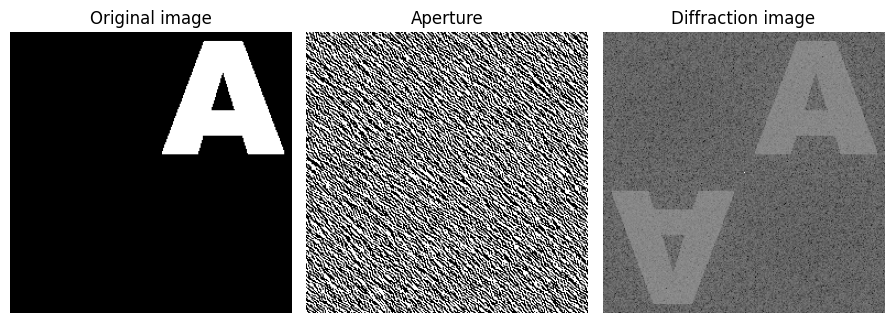

In [3]:
import cv2
import numpy as np
from matplotlib import pyplot as plt

# Settings
dir_path = '/content/drive/MyDrive/fft'    # File directory
file_name = 'A3.png'                       # Original image filename
tiled_file_name = 'Aparture.png'           # Filename for saving the tiled aperture pattern
diffraction_file_name = 'Diffraction.png'  # Filename for saving the calculated diffraction image
grid_size = (1, 1)                         # Number of tilings (vertical repeats, horizontal repeats)
np.random.seed(42)                         # Fix the random seed for reproducible results

# Load image file
img_path = f'{dir_path}/{file_name}'       # Generate file path
img = cv2.imread(img_path, 0)              # Load image in grayscale
img = np.where(img <= 127, 0, 255)         # Binarization

# Apply random phase
random_phase = np.exp(1j * 2 * np.pi * np.random.rand(*img.shape)) # Calculate random phase
f_img_random = img * random_phase          # Apply random phase while keeping amplitude unchanged

# 2D Inverse Fourier Transform (IFFT)
ifft_img = np.fft.ifftshift(f_img_random)  # Shift origin to center before FFT
ifft_img = np.fft.ifft2(ifft_img)          # 2D Inverse Fourier Transform
ifft_img = np.fft.fftshift(ifft_img)       # Shift DC component to the image center

# Mask operation (Binarization)
f_amp = np.real(ifft_img)                  # Use only the real part
threshold = f_amp.mean()                   # Calculate the mean value
binary_image = np.where(f_amp <= threshold, 0, 255) # Binarize using the mean as threshold

# 2D Fourier Transform (FFT)
img_back = np.fft.ifftshift(binary_image)  # Shift origin to center before FFT
img_back = np.fft.fft2(img_back)          # 2D Fourier Transform
img_back = np.fft.fftshift(img_back)       # Shift back to center
img_back2 = np.log1p(np.abs(img_back))    # Use log scale to increase contrast

# Save the tiled image
tiled_image = np.tile(binary_image, grid_size)
tiled_image_path = f'{dir_path}/{tiled_file_name}'
cv2.imwrite(tiled_image_path, tiled_image.astype(np.uint8))
print(f"Saved tiled image ({grid_size[0]}x{grid_size[1]}): {tiled_image_path}")
print(f"Size: {tiled_image.shape}")

# Save the diffraction image (Normalized to 0-255)
img_back2_normalized = cv2.normalize(img_back2, None, 0, 255, cv2.NORM_MINMAX)
diffraction_image_path = f'{dir_path}/{diffraction_file_name}'
cv2.imwrite(diffraction_image_path, img_back2_normalized.astype(np.uint8))
print(f"Saved diffraction image: {diffraction_image_path}")

# Plot the results
plt.figure(figsize=(12, 4))

plt.subplot(1, 4, 1)
plt.imshow(img, cmap='gray')
plt.title("Original image")
plt.axis('off')

#plt.subplot(1, 4, 2)
#plt.imshow(f_amp_scaled, cmap='gray')
#plt.title("Real Part of IFFT")
#plt.axis('off')

plt.subplot(1, 4, 2)
plt.imshow(binary_image, cmap='gray')
plt.title("Aperture")
plt.axis('off')

plt.subplot(1, 4, 3)
plt.imshow(img_back2, cmap='gray')
plt.title("Diffraction image")
plt.axis('off')

plt.tight_layout()
plt.show()